# 02 — Annotation alignment and baseline evaluation

Perera E. V. · J26-DS-339 · recorded 2026-10-21.

This notebook reviews an executed, small baseline pilot. Methods live in reusable Python modules. Reports preserve recording IDs, configurations, implementation hashes and versions. The official TEST split is not evaluated. These are pilot results, not a trained CNN–Transformer result or a full HumTrans benchmark.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt
import librosa
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/melody_understanding').exists())
sys.path.insert(0,str(ROOT/'src'))
from melody_understanding.annotations import read_midi_notes
from melody_understanding.evaluation import notes_with_smoothing, score_notes
RESULT = ROOT/'experiments/vishwa/results/pilot_001'
summary = json.loads((RESULT/'summary.json').read_text())
records = json.loads((RESULT/'per_recording.json').read_text())
cohort = json.loads((RESULT/'cohort.json').read_text())
audit = json.loads((ROOT/'experiments/vishwa/results/alignment_audit.json').read_text())
print('Pilot configuration:',summary['config'])
print('TRAIN / VALID recording counts:',{k:len(v) for k,v in cohort['ids'].items()})
assert set(cohort['ids']) == {'TRAIN','VALID'}


Pilot configuration: {'protocol': 'vishwa-pyin-pilot-v1', 'seed': 339, 'train_per_singer': 2, 'valid_per_singer': 1, 'smoothing_widths': [1, 3, 5], 'selection_metric': 'train_macro_note_f1', 'selection_tiebreak': 'smallest_width', 'screening': 'no manifest flags', 'preprocessing': 'baseline defaults, no trimming', 'note_min_duration_s': 0.06, 'onset_tolerance_s': 0.05, 'pitch_tolerance_cents': 50, 'offset_ratio': 0.2, 'offset_min_tolerance_s': 0.05, 'test_policy': 'no predictions or metrics on TEST', 'scope': 'small deterministic pilot, not full-split benchmark'}
TRAIN / VALID recording counts: {'TRAIN': 20, 'VALID': 10}


## Independent annotation audit and correction

The first exploration notebook used a custom tempo parser. At tick zero, sorting tuples by tempo value allowed the fallback 500,000 μs/beat to override faster explicit tempos. The earlier 834 tail-overrun finding is retracted. Mido and PrettyMIDI agree on all notes within 1e-7 seconds; PrettyMIDI shares Mido's low-level parser, so this cross-check concerns tempo/note interpretation. Structural consistency does not prove perceptual alignment.

In [2]:
print('Pairs:',audit['wav_count'],'Reference notes:',audit['note_count'])
print('Audit flags:',audit['flag_counts'])
print('Largest tail difference (seconds):',audit['max_tail_overrun_s'])


Pairs: 14614 Reference notes: 391595
Audit flags: {}
Largest tail difference (seconds): 2.2675736971677907e-05


## Controlled comparison

Two TRAIN examples per singer were selected with seed 339. Only TRAIN macro note F1 selected the smoothing width; that choice was saved before VALID inference. The pilot compares widths 1, 3 and 5 frames (about 11.6, 34.8 and 58.0 ms windows). Smoothing stays inside voiced regions and never bridges rests.

Note F1 uses one-to-one onset/pitch matches at 50 ms and 50 cents. Offset F1 additionally checks offsets within max(20% of reference duration, 50 ms). Frame agreement uses held MIDI pitches, not continuous ground-truth vocal F0. Each aggregate is a mean across recordings.

TRAIN width=1 n=20 | note F1=0.0476 | offset F1=0.0212 | MIDI frame agreement=0.3017
TRAIN width=3 n=20 | note F1=0.0480 | offset F1=0.0230 | MIDI frame agreement=0.3017
TRAIN width=5 n=20 | note F1=0.0489 | offset F1=0.0230 | MIDI frame agreement=0.3017
VALID width=1 n=10 | note F1=0.0281 | offset F1=0.0220 | MIDI frame agreement=0.3094
VALID width=5 n=10 | note F1=0.0276 | offset F1=0.0216 | MIDI frame agreement=0.3094
Frozen selected width: 5


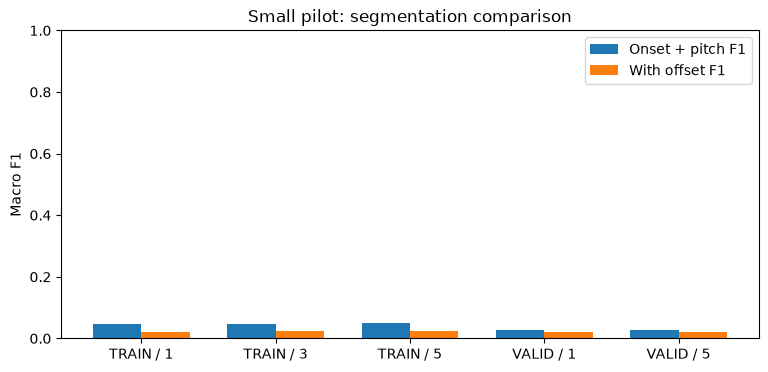

In [3]:
for row in summary['aggregate']:
    print(f"{row['split']} width={row['width']} n={row['n']} | note F1={row['note_f1']:.4f} | offset F1={row['note_offset_f1']:.4f} | MIDI frame agreement={row['midi_frame_pitch_agreement_50c']:.4f}")
print('Frozen selected width:',summary['selected_width'])
fig, ax = plt.subplots(figsize=(9,4))
labels=[f"{r['split']} / {r['width']}" for r in summary['aggregate']]
x=np.arange(len(labels))
ax.bar(x-.18,[r['note_f1'] for r in summary['aggregate']],.36,label='Onset + pitch F1')
ax.bar(x+.18,[r['note_offset_f1'] for r in summary['aggregate']],.36,label='With offset F1')
ax.set(xticks=x,xticklabels=labels,ylim=(0,1),ylabel='Macro F1',title='Small pilot: segmentation comparison')
ax.legend();plt.show()


## Recompute one saved example

Reload cached frame predictions and the original reference MIDI, then recompute note scoring. This checks that the reported score follows from the preserved features and current evaluation code.

In [4]:
row = next(r for r in records if r['split']=='TRAIN' and r['smoothing_width']==summary['selected_width'])
with np.load(ROOT/'datasets/humtrans/derived/research/pilot_features'/f"{row['key']}.npz") as f:
    features={k:f[k] for k in f.files}
reference,_=read_midi_notes(ROOT/'datasets/humtrans/downloads/midi_data'/f"{row['key']}.mid")
predicted=notes_with_smoothing(features,row['duration_s'],row['smoothing_width'])
recomputed=score_notes(reference,predicted)
assert np.isclose(recomputed['note_f1'],row['note_f1'])
print(row['key'],recomputed)


F01_0101_0001_1_D {'note_precision': 0.0, 'note_recall': 0.0, 'note_f1': 0.0, 'note_offset_f1': 0.0}


## Representative stronger and weaker TRAIN cases

Choose the highest and lowest note F1 within the selected TRAIN variant. Plots help reveal onset delays, pitch errors, fragmentation, and repeated-note failures. They do not establish the cause without further controlled investigation.

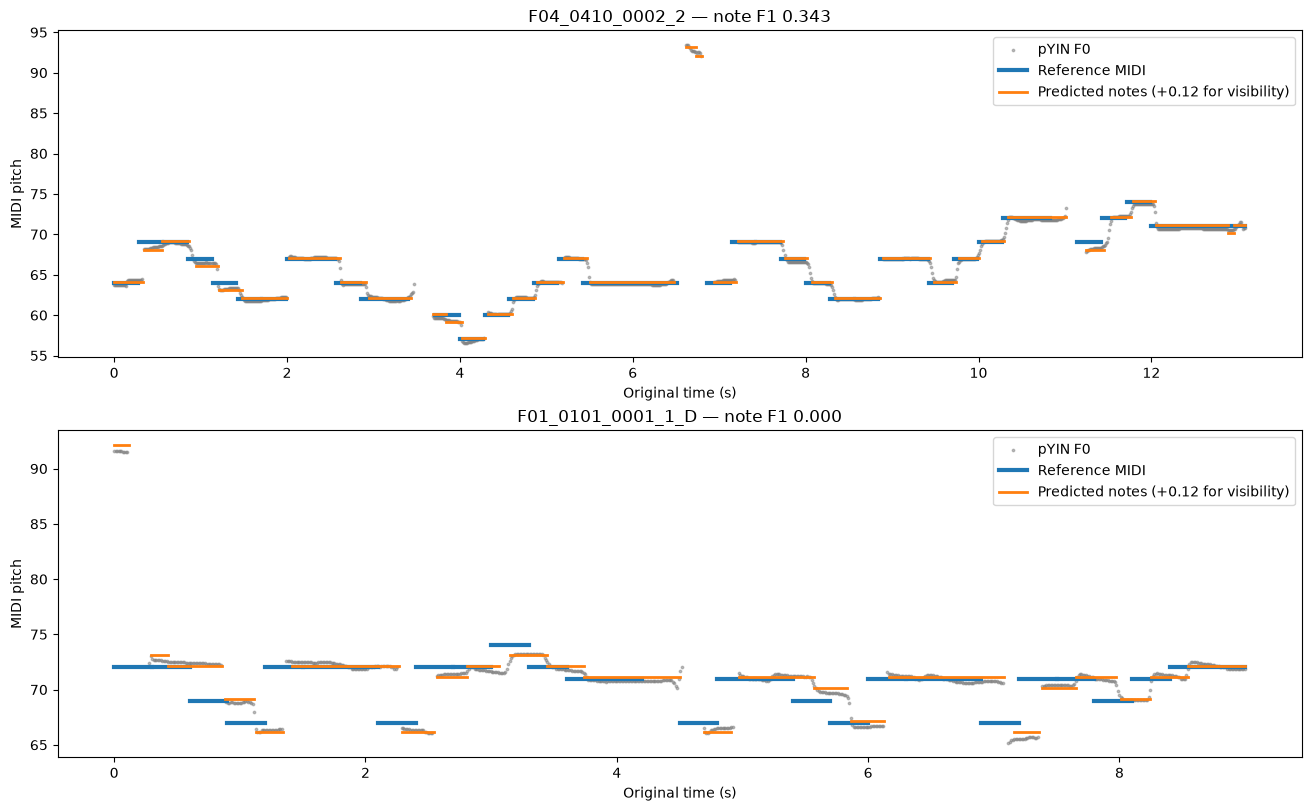

In [5]:
selected=[r for r in records if r['split']=='TRAIN' and r['smoothing_width']==summary['selected_width']]
cases=[max(selected,key=lambda r:r['note_f1']),min(selected,key=lambda r:r['note_f1'])]
fig,axes=plt.subplots(2,1,figsize=(13,8),constrained_layout=True)
for ax,row in zip(axes,cases):
    with np.load(ROOT/'datasets/humtrans/derived/research/pilot_features'/f"{row['key']}.npz") as f:
        features={k:f[k] for k in f.files}
    ref,_=read_midi_notes(ROOT/'datasets/humtrans/downloads/midi_data'/f"{row['key']}.mid")
    mask=features['voiced'] & np.isfinite(features['f0_hz'])
    ax.scatter(features['times_s'][mask],librosa.hz_to_midi(features['f0_hz'][mask]),s=3,c='gray',alpha=.5,label='pYIN F0')
    for i,(start,end,pitch) in enumerate(ref):
        ax.plot([start,end],[pitch,pitch],color='tab:blue',lw=3,label='Reference MIDI' if i==0 else None)
    pred=notes_with_smoothing(features,row['duration_s'],row['smoothing_width'])
    for i,n in enumerate(pred):
        ax.plot([n['onset_s'],n['onset_s']+n['duration_s']],[n['pitch_midi']+.12]*2,color='tab:orange',lw=2,label='Predicted notes (+0.12 for visibility)' if i==0 else None)
    ax.set(title=f"{row['key']} — note F1 {row['note_f1']:.3f}",xlabel='Original time (s)',ylabel='MIDI pitch')
    ax.legend()
plt.show()


## Interpretation and limitations

No test-set performance or superiority over the proposal's published benchmarks is claimed. Inspect differences between TRAIN and VALID: a TRAIN gain may fail to generalize. MIDI-defined rests and quantized pitches are approximate references for continuous vocal pitch. All singers appear in each official split, so this pilot does not assess unseen-singer generalization. Decisions and the next controlled experiment are maintained in `docs/vishwa/research_progress.md`.

## Recorded decision from this pilot

TRAIN note F1 increased only from **0.047592** (width 1) to **0.048927** (width 5). On the frozen VALID cohort it decreased from **0.028077** to **0.027592**. Therefore smoothing is not adopted as the default. This negative result is preserved; neither score supports a claim of a strong transcription model.

The next diagnostic reuses TRAIN predictions to compare octave-sensitive and pitch-class agreement and sensitivity to onset tolerance. This will change the scoring criteria, not the model; any resulting higher numbers must be presented as diagnostics rather than improved accuracy.